# Continuous Optimization in Data Science: Assignment 4

**Group 3**

**Group members:**
- Simon Carlén
- Alvin Stallgård

## Q1.1 Sparsity of an image under the DCT

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.fftpack as transform
from sklearn.datasets import load_diabetes

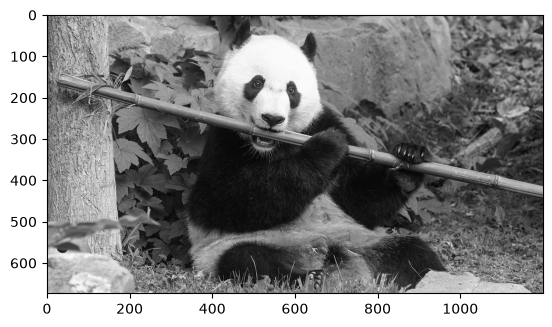

(674, 1200)


In [60]:
# plt.imread gives values in [0, 1], scale to 0-255 so that t in [1e4, 1e7] makes sense
img = plt.imread('panda.png')[:, :, :3] * 255
# generating grayscale image:
bw_img = np.sum(img, 2) / 3

# (a) 2D DCT transform
coeffs = transform.dct(transform.dct(bw_img, axis=0), axis=1)
plt.imshow(bw_img, cmap='gray')
plt.show()
print(coeffs.shape)

In [75]:
# (b) Threshold the coefficients with t and calculate the fraction of nonzero coefficients
thresholds = [1e4, 5e4, 1e5, 5e5, 1e6, 5e6, 1e7]
shares = {}

for t in thresholds:
    approx_coeffs = coeffs.copy()
    approx_coeffs[np.abs(approx_coeffs) < t] = 0
    share = np.count_nonzero(approx_coeffs)/np.size(approx_coeffs)
    shares[t] = (approx_coeffs, share)
    print(f"Threshold: {int(t)} gives the share: {share}")

Threshold: 10000 gives the share: 0.5535262116716123
Threshold: 50000 gives the share: 0.1078560830860534
Threshold: 100000 gives the share: 0.02988996043521266
Threshold: 500000 gives the share: 0.0019275469831849653
Threshold: 1000000 gives the share: 0.0006911473788328388
Threshold: 5000000 gives the share: 5.440158259149357e-05
Threshold: 10000000 gives the share: 2.1018793273986153e-05


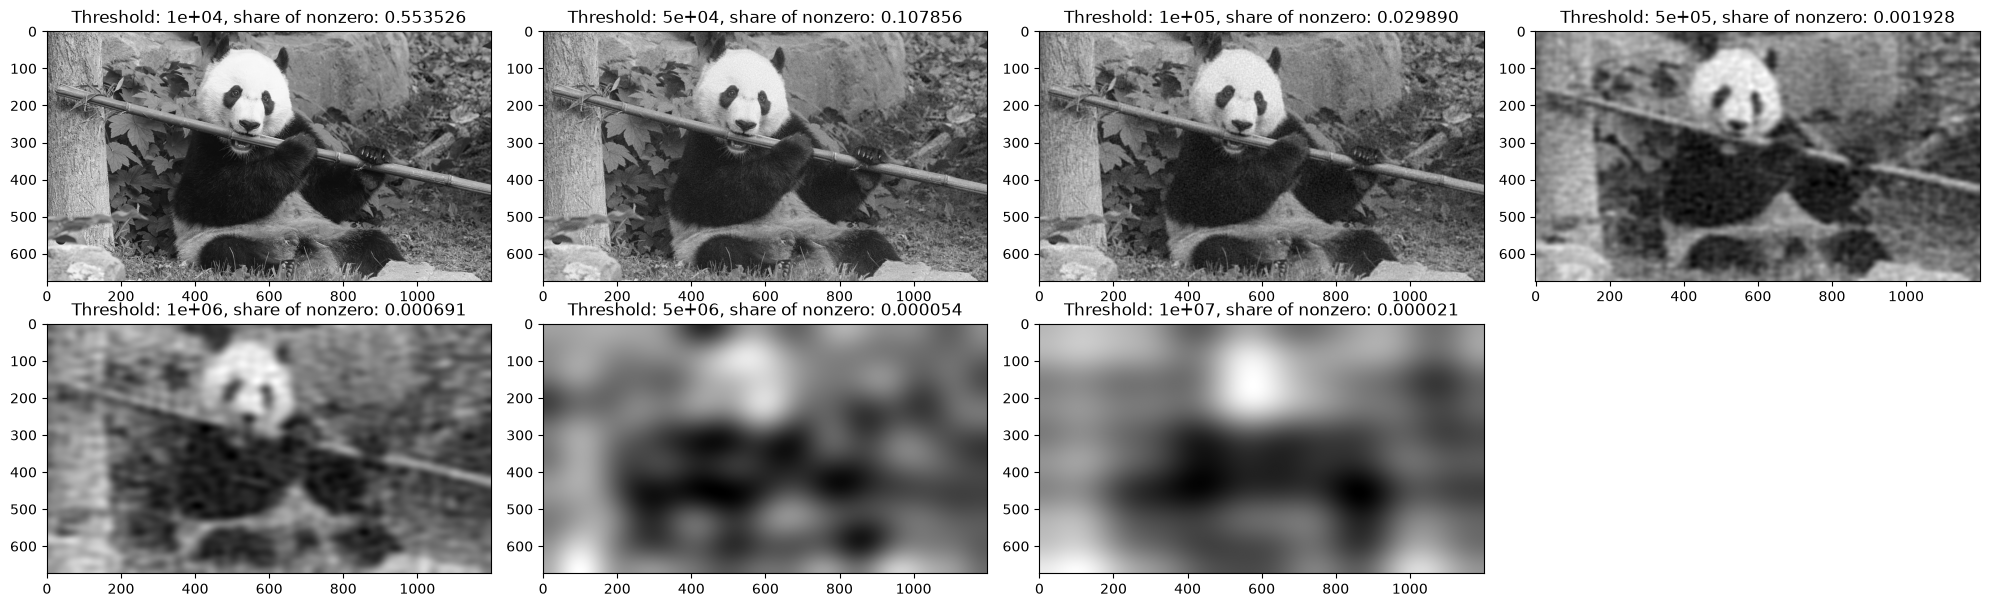

In [77]:
# (c) Apply the 2D inverse DCT, idct(idct(approx_coeffs, axis=1), axis=0), and plot it for larger thresholds
fig, axes = plt.subplots(2, 4, figsize=(20, 6))
axes = axes.flatten()

i = 0
for t, (approx_coeffs, share) in shares.items():
    approx_img=transform.idct(transform.idct(approx_coeffs, axis=1),axis=0)
    axes[i].imshow(approx_img, cmap='gray')
    axes[i].set_title(f"Threshold: {t:.0e}, share of nonzero: {share:.6f}")
    i += 1

axes[7].axis('off')
plt.tight_layout()
plt.show()

#### Report

**(d) Thresholds with their fraction of nonzero coefficients and the corresponding images.**

The table shows the share of nonzero DCT coefficients for the thresholds we tried. The corresponding images are shown in (c) above.

| Threshold $t$ | Share of nonzero coefficients |
|---|---|
| $10^4$ | 0.554 |
| $5 \cdot 10^4$ | 0.108 |
| $10^5$ | 0.0299 |
| $5 \cdot 10^5$ | 0.00193 |
| $10^6$ | 0.00069 |
| $5 \cdot 10^6$ | 0.000054 |
| $10^7$ | 0.000021 |

Already at $t = 10^5$ only about 3 percent of the coefficients are nonzero and the image looks almost the same as the original. At $t = 5 \cdot 10^5$ only 0.2 percent are left and the panda is still easy to see, but the image gets a bit noisy and the background loses detail. At $t = 10^6$ the image is blurry but we can still see that it is a panda. At $t = 5 \cdot 10^6$ and $t = 10^7$ the image is unrecognizable and only some light and dark areas are left. So the image can be made very sparse in the DCT domain, down to under 0.1 percent nonzero coefficients, before it becomes hard to recognize, and the limit is somewhere between $t = 10^6$ and $t = 5 \cdot 10^6$. This works because most of the information in a natural image is in a small number of low frequency coefficients.

## Q1.2 LASSO

**(a) Proximal operator of the $\ell_1$ norm**

**(b) Iterative soft thresholding (ISTA)**

**(c) Cyclic coordinate descent (CCD)**

**(d) ADMM**

## Q1.3 LASSO on the diabetes dataset

In [63]:
X, y = load_diabetes(return_X_y=True)
print(X.shape)

(442, 10)


In [64]:
def soft_threshold(x, lam):
    # shrinkage operator S_lam(x) in (3)
    return x


def ISTA(X, y, lam, step, T):
    n, m = X.shape
    theta = np.zeros(m)
    values = np.zeros(T)

    for t in range(T):
        # gradient step on LS(theta), then soft thresholding
        # objective value
        values[t] = 0

    return theta, values


def CCD(X, y, lam, T):
    n, m = X.shape
    theta = np.zeros(m)
    values = np.zeros(T)

    for t in range(T):
        # one full cycle over k: e_k in (6), then update theta_k by (5)
        # objective value
        values[t] = 0

    return theta, values


def ADMM(X, y, lam, rho, T):
    n, m = X.shape
    theta1 = np.zeros(m)
    theta2 = np.zeros(m)
    u = np.zeros(m)
    values = np.zeros(T)

    for t in range(T):
        # theta1, theta2 and u updates in (7)
        # objective value
        values[t] = 0

    return theta2, values

In [65]:
# (a) Check that the objective converges for each method and tune the step size and rho

In [66]:
# (b)i. Value of all 10 variables vs lambda, ADMM until the variables do not change much

In [67]:
# (b)ii. Optimality gap vs iterations (first 100) for a lambda with 5 nonzero variables
# optimal value from a long ADMM run, one CCD iteration is a full cycle

#### Report

**(a) Implementation and tuning of the hyperparameters.**

**(b)i. Value of the variables vs $\lambda$.**

**(b)ii. Optimality gap vs iterations.**